# A Comparative Machine Learning Framework for Predicting Childhood Pneumonia Prevalence

**Integrating Household Crowding, Vaccination Status, and Passive Smoking as Socio-Environmental Determinants**



---

### Complete research workflow (Methods overview)

| Stage | Description |
|-------|-------------|
| 1 | Data loading from the clinical registry |
| 2 | Exploratory data analysis (prevalence, missingness) |
| 3 | Outcome definition + construction of 28 predictors |
| 4 | Missing-value handling (exclusion of critical missingness + median imputation inside CV) |
| 5 | Feature selection rationale |
| 6 | Stratified train-test split (80/20, seed = 42) |
| 7 | Pre-processing pipeline (impute, scale, SMOTE) fitted only on training data |
| 8 | Definition algorithms and their hyper-parameter search spaces |
| 9 | Hyper-parameter optimisation (RandomizedSearchCV, ROC-AUC, 5-fold stratified) |
| 10 | Model training and selection (highest nested-CV AUC) |
| 11 | Performance evaluation on hold-out test set + train-test gap |
| 12 | Nested cross-validation (unbiased generalisation estimate) |
| 13 | Calibration assessment (reliability curves, Brier score) |
| 14 | Feature importance, SHAP and LIME |
| 15 | Sensitivity analyses (remove Chest X-ray; narrow outcome definition) |
| 16 | Recording of final hyper-parameters and software versions |


## 1. Setup, imports and reproducibility settings

 Fixed random seed, explicit library versions and deterministic behaviour are required for exact reproduction of results.


In [1]:
!pip install xgboost lightgbm shap imbalanced-learn lime openpyxl -q

import warnings
warnings.filterwarnings("ignore")

import os, sys, platform, json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import (
    train_test_split, StratifiedKFold, RandomizedSearchCV, cross_val_score
)
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, brier_score_loss, classification_report
)
from sklearn.calibration import calibration_curve
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import (
    RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier
)
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.neural_network import MLPClassifier
from sklearn.base import clone

from xgboost import XGBClassifier
from lightgbm import LGBMClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap
from lime.lime_tabular import LimeTabularExplainer
from scipy.stats import randint, uniform, loguniform

SEED = 42
np.random.seed(SEED)

os.makedirs("figs", exist_ok=True)
os.makedirs("results", exist_ok=True)

VERSIONS = {
    "python": sys.version.split()[0],
    "platform": platform.platform(),
    "numpy": np.__version__,
    "pandas": pd.__version__,
    "sklearn": __import__("sklearn").__version__,
    "xgboost": __import__("xgboost").__version__,
    "lightgbm": __import__("lightgbm").__version__,
    "imblearn": __import__("imblearn").__version__,
    "shap": shap.__version__,
}
print("Software versions:")
for k, v in VERSIONS.items():
    print(f"  {k:12s}: {v}")


  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
Software versions:
  python      : 3.13.18
  platform    : Linux-6.6.159+-x86_64-with-glibc2.39
  numpy       : 2.4.6
  pandas      : 2.2.3
  sklearn     : 1.6.1
  xgboost     : 3.4.1
  lightgbm    : 4.6.0
  imblearn    : 0.14.2
  shap        : 0.54.1


## 2. Data loading
**Source:** Clinical registry of children admitted with respiratory symptoms (file `BD_IRA.xlsx`).

**Unit of analysis:** One row = one patient admission.


In [2]:
DATA_PATH = "BD_IRA.xlsx"
df = pd.read_excel(DATA_PATH)
print(f"Raw shape: {df.shape[0]} patients x {df.shape[1]} columns")
df.head(10)


Raw shape: 801 patients x 91 columns


,ID PATIENT,Admission date,Age (months),Gender,Medical insurance,Length of stay (Days),Meets criteria for clinical pneumonia,Number of persons living in house,Number of siblings,Number of rooms in house,...,HIV testing,HIV test results,Blood culture results,Nasopharyngeal aspirate culture (NPA) Identification 1,Nasopharyngeal aspirate culture (NPA) Identification 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 1,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 2,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 3,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 4,Detection of DNA/RNA (TrueScience Respifinder Pathogen Identification Panel) Allele 5
0,PN0001,2010-11-02,41,Male,No,57,Yes,5.0,3.0,1.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
1,PN0002,2010-11-02,56,Female,No,3,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,Parainfluenza viruses 3,Parainfluenza viruses 1,Adenovirus,Rhinovirus,N/A
2,PN0003,2010-11-03,26,Male,Yes,12,Yes,6.0,4.0,2.0,...,No,NaN,Negative,Negative,NaN,CoronavirusesNL63,NaN,N/A,N/A,N/A
3,PN0004,2010-11-04,2,Male,No,22,Yes,7.0,4.0,1.0,...,No,NaN,Pseudomonas oryzihabitans,Negative,NaN,RSV-B,Parainfluenza viruses 3,Rhinovirus,N/A,N/A
4,PN0005,2010-11-05,15,Male,No,7,Yes,5.0,3.0,2.0,...,No,NaN,Negative,Negative,NaN,Adenovirus,NaN,N/A,N/A,N/A
5,PN0006,2010-11-05,15,Male,Yes,6,Yes,5.0,3.0,3.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
6,PN0007,2010-11-06,12,Male,No,5,Yes,5.0,3.0,2.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
7,PN0008,2010-11-06,31,Male,No,10,Yes,7.0,5.0,2.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A
8,PN0009,2010-11-08,16,Female,Yes,11,Yes,5.0,2.0,2.0,...,No,NaN,Negative,Negative,NaN,Parainfluenza viruses 2,N/A,N/A,N/A,N/A
9,PN0010,2010-11-08,4,Male,No,3,Yes,6.0,2.0,3.0,...,No,NaN,Negative,Negative,NaN,Rhinovirus,N/A,N/A,N/A,N/A


## 3. Exploratory data analysis

**Purpose:** Quantify outcome prevalence and missing-data patterns before any modelling decisions.


In [3]:
print("Top 10 values of 'Main diagnostic ':")
print(df["Main diagnostic "].value_counts().head(10))

print("\nTop 12 columns by percentage of missing values:")
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
print(missing_pct.head(12).round(1))


Top 10 values of 'Main diagnostic ':
Main diagnostic 
Asthma attack                  285
Dyspneic pneumopathy           135
Pneumonia                       79
Bronchiolitis                   74
Laryngeal dyspnea               74
Bronchiolitis (1st episode)     36
Wheezing dyspnea                24
Bronchiolitis (3rd episode)     19
Bronchiolitis (2nd episode)     17
Infant asthma                   11
Name: count, dtype: int64

Top 12 columns by percentage of missing values:
HIV test results                                                                                                                                                                 99.4
Location of pleural effusion                                                                                                                                                     99.1
Confirmation of dehydration                                                                                                                                  

## 4. Outcome definition and feature engineering

### 4.1 Binary outcome
Pneumonia-positive if the main diagnostic belongs to the following clinically defined set:

`Pneumonia`, `Dyspneic pneumopathy`, `Staphylococcal pneumonia`,  
`Bronchiolitis + Pneumonia`, `Asthma attack + Pneumonia`,  
`Pleuropneumonitis`, `Interstitial pneumopathy`.

### 4.2 Predictor set (28 features)
Features were chosen a priori on clinical and socio-environmental grounds (no data-driven filtering at this stage):

- **Biomarkers:** CRP, Procalcitonin, SaO2, Temperature, Respiratory rate, Heart rate  
- **Clinical signs:** Fever, Crackles, Wheezing, Nasal flaring, Cyanosis  
- **Demographics / history:** Age, Gender, Siblings, Prematurity, Breastfeeding, Prior respiratory admission  
- **Socio-environmental (study focus):** Household size, Rooms, Persons-per-room (crowding), Smokers at home, Vitamin A  
- **Vaccination:** Full / Partial / None (one-hot) + Hib and pneumococcal dose counts  
- **Imaging:** Chest X-ray finding (ordinal: Normal to Endpoint pneumonia)


In [4]:
pneumonia_diags = [
    "Pneumonia", "Dyspneic pneumopathy", "Staphylococcal pneumonia",
    "Bronchiolitis + Pneumonia", "Asthma attack + Pneumonia",
    "Pleuropneumonitis", "Interstitial pneumopathy"
]
df["target"] = df["Main diagnostic "].isin(pneumonia_diags).astype(int)
print("Outcome distribution:")
print(df["target"].value_counts())
print(f"Prevalence: {df['target'].mean():.1%}")

def yn(col):
    """Map Yes/No to 1/0; preserve missing as NaN (imputed later inside pipeline)."""
    s = df[col].astype(str).str.strip().str.lower()
    return (s == "yes").astype(float).where(s.notna() & (s != "nan"), np.nan)

feat = pd.DataFrame(index=df.index)

feat["CRP"]             = pd.to_numeric(df["C-reactive protein"], errors="coerce")
feat["Procalcitonin"]   = pd.to_numeric(df["Procalcitonin"], errors="coerce")
feat["SaO2"]            = pd.to_numeric(df["Oxygen saturation (SaO2) at admission"], errors="coerce")
feat["Temperature"]     = pd.to_numeric(df["Axillary temperature (C)"], errors="coerce") if "Axillary temperature (C)" in df.columns else pd.to_numeric(df["Axillary temperature (°C)"], errors="coerce")
feat["RespiratoryRate"] = pd.to_numeric(df["Respiratory rate"], errors="coerce")
feat["HeartRate"]       = pd.to_numeric(df["Heart rate"], errors="coerce")

feat["Fever"]        = yn("History of fever")
feat["Crackles"]     = yn("Crackles")
feat["Wheezing"]     = yn("Wheezing")
feat["NasalFlaring"] = yn("Nasal flaring")
feat["Cyanosis"]     = yn("Cyanosis")

feat["Age"]          = pd.to_numeric(df["Age (months)"], errors="coerce")
feat["Gender"]       = (df["Gender "].astype(str).str.strip() == "Male").astype(int)
feat["Siblings"]     = pd.to_numeric(df["Number of siblings"], errors="coerce")
feat["Prematurity"]  = yn("Health history : Prematurity                      ")
feat["Breastfed"]    = yn("Breastfeeding")
feat["PriorRespAdm"] = yn("Health history : Prior admission because of respiratory condition")

feat["HouseholdSize"]  = pd.to_numeric(df["Number of persons living in house"], errors="coerce")
feat["Rooms"]          = pd.to_numeric(df["Number of rooms in house"], errors="coerce")
feat["PersonsPerRoom"] = feat["HouseholdSize"] / feat["Rooms"].replace(0, np.nan)
feat["SmokersAtHome"]  = yn("Smokers at home")
feat["VitaminA"]       = yn("Vitamin A supplementation ")

vax = df["Age-appropriate vaccinations"].astype(str).str.strip()
feat["Vacc_Full"]    = (vax == "Yes").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["Vacc_Partial"] = (vax == "Partially").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["Vacc_None"]    = (vax == "No").astype(float).where(vax.notna() & (vax != "nan"), np.nan)
feat["HibDoses"]     = pd.to_numeric(df["Number of Hib vaccine doses received"], errors="coerce")
feat["PneumoDoses"]  = pd.to_numeric(df["Number of pneumococcal vaccine doses received"], errors="coerce")

xray_map = {"Normal": 0, "NF": 1, "Other infiltrates": 2, "Endpoint pneumonia": 3}
feat["ChestXray"] = df["Chest X-ray finding"].astype(str).str.strip().map(xray_map)

feat["target"] = df["target"].values
FEATURE_COLS = [c for c in feat.columns if c != "target"]
print(f"\nEngineered {len(FEATURE_COLS)} predictors.")
feat.head(3)


Outcome distribution:
target
0    582
1    219
Name: count, dtype: int64
Prevalence: 27.3%

Engineered 28 predictors.


,CRP,Procalcitonin,SaO2,Temperature,RespiratoryRate,HeartRate,Fever,Crackles,Wheezing,NasalFlaring,...,PersonsPerRoom,SmokersAtHome,VitaminA,Vacc_Full,Vacc_Partial,Vacc_None,HibDoses,PneumoDoses,ChestXray,target
0,79.0,1.35,80.0,37.8,72.0,143.0,1.0,0.0,0.0,1.0,...,5.0,1.0,1.0,1.0,0.0,0.0,3,0,3,1
1,46.0,0.10,91.0,38.0,84.0,142.0,1.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,0,1,0
2,4.0,0.10,99.0,37.6,60.0,130.0,0.0,0.0,1.0,1.0,...,3.0,1.0,1.0,1.0,0.0,0.0,3,1,2,0


## 5. Missing-value handling

**Rule set (pre-specified):**
1. Any record missing one or more of the four *critical* variables (CRP, Age, RespiratoryRate, HouseholdSize) is excluded.  
2. All other missing values are left as NaN and will be imputed with the **median of the training fold only** (inside the modelling pipeline).  
   This prevents information leakage from the test set or from outer-CV validation folds.


In [5]:
CRITICAL = ["CRP", "Age", "RespiratoryRate", "HouseholdSize"]

miss_summary = pd.DataFrame({
    "n_missing": feat[FEATURE_COLS].isna().sum(),
    "pct_missing": (feat[FEATURE_COLS].isna().mean() * 100).round(2)
}).sort_values("pct_missing", ascending=False)
print("Missingness before exclusion (top 10):")
display(miss_summary.head(10))

n_before = len(feat)
feat = feat.dropna(subset=CRITICAL + ["target"]).copy()
X = feat[FEATURE_COLS].copy()
y = feat["target"].values

print(f"\nRecords retained: {n_before} -> {len(feat)} (excluded {n_before - len(feat)})")
print(f"Cells still missing (will be imputed inside pipeline): {int(X.isna().sum().sum())}")
print(f"Class counts: {dict(pd.Series(y).value_counts())} | prevalence {y.mean():.1%}")


Missingness before exclusion (top 10):


,n_missing,pct_missing
SaO2,34,4.24
Procalcitonin,17,2.12
HeartRate,13,1.62
Rooms,4,0.50
VitaminA,4,0.50
Vacc_Full,4,0.50
Vacc_Partial,4,0.50
Vacc_None,4,0.50
PersonsPerRoom,4,0.50
Temperature,3,0.37



Records retained: 801 -> 799 (excluded 2)
Cells still missing (will be imputed inside pipeline): 86
Class counts: {0: np.int64(581), 1: np.int64(218)} | prevalence 27.3%


## 6. Feature selection rationale

All 28 engineered features were retained.  
They were chosen on clinical and socio-environmental grounds *before* model fitting; no univariate filter or recursive feature elimination was applied in the primary analysis.  
A simple correlation check is shown for transparency only.


In [6]:
corr_with_target = X.corrwith(pd.Series(y, index=X.index)).abs().sort_values(ascending=False)
print("Absolute Pearson / point-biserial correlation with target (top 12):")
print(corr_with_target.head(12).round(3))

selected_features = FEATURE_COLS.copy()
print(f"\nFeatures used in all subsequent models: {len(selected_features)}")


Absolute Pearson / point-biserial correlation with target (top 12):
Wheezing         0.536
Temperature      0.423
CRP              0.408
ChestXray        0.385
Fever            0.264
Age              0.222
Crackles         0.215
SaO2             0.178
PriorRespAdm     0.148
Procalcitonin    0.121
Vacc_Full        0.118
HibDoses         0.110
dtype: float64

Features used in all subsequent models: 28


## 7. Stratified train-test split

- Ratio: 80% training / 20% test  
- Stratification on the outcome preserves prevalence  
- Random seed fixed at 42  
- The test set is used **only once**, after all model development is complete


In [7]:
X_train, X_test, y_train, y_test = train_test_split(
    X[selected_features], y,
    test_size=0.20,
    random_state=SEED,
    stratify=y
)
print(f"Training set : {len(y_train)} patients (prevalence {y_train.mean():.1%})")
print(f"Test set     : {len(y_test)} patients (prevalence {y_test.mean():.1%})")


Training set : 639 patients (prevalence 27.2%)
Test set     : 160 patients (prevalence 27.5%)


## 8. Pre-processing pipeline (no leakage)

Every estimator is wrapped in the following pipeline. All steps are fitted **exclusively on the data visible inside each training fold**:

1. `SimpleImputer(strategy="median")`  
2. `StandardScaler()`  
3. `SMOTE(random_state=42)`  
4. Classifier

Because SMOTE and scaling occur after the split (and inside CV), the test set and outer-CV validation folds remain completely untouched.


In [8]:
def make_pipe(estimator):
    """Impute -> Scale -> SMOTE -> Classifier. Fitted only on training data."""
    return ImbPipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler",  StandardScaler()),
        ("smote",   SMOTE(random_state=SEED)),
        ("clf",     estimator)
    ])

print("Pipeline factory defined.")


Pipeline factory defined.


## 9. Algorithms and hyper-parameter search spaces

Eleven algorithms covering linear, tree, ensemble, kernel, instance-based, probabilistic and neural families were evaluated.

### 9.1 Fixed-specification models (no tuning)

| Algorithm | Hyper-parameters (fixed) |
|-----------|--------------------------|
| Decision Tree | max_depth=5, min_samples_split=10 |
| Gradient Boosting | n_estimators=150, learning_rate=0.1 |
| AdaBoost | n_estimators=100 |
| SVM (RBF) | library defaults, probability=True |
| k-NN | n_neighbors=7 |
| Gaussian Naive Bayes | defaults |
| MLP | hidden_layer_sizes=(100,50), max_iter=500 |


In [10]:
# 9.1 Definition and evaluation of fixed-specification (untuned) models

# Define the base classifiers with fixed specifications
fixed_classifiers = {
    "Logistic Regression (Fixed)": LogisticRegression(max_iter=2000, random_state=SEED),
    "Decision Tree (Fixed)": DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=SEED),
    "Random Forest (Fixed)": RandomForestClassifier(n_estimators=100, random_state=SEED, n_jobs=-1),
    "XGBoost (Fixed)": XGBClassifier(eval_metric="logloss", verbosity=0, random_state=SEED),
    "LightGBM (Fixed)": LGBMClassifier(verbose=-1, random_state=SEED),
    "Gradient Boosting (Fixed)": GradientBoostingClassifier(n_estimators=150, learning_rate=0.1, random_state=SEED),
    "AdaBoost (Fixed)": AdaBoostClassifier(n_estimators=100, random_state=SEED),
    "SVM (Fixed)": SVC(probability=True, random_state=SEED),
    "k-NN (Fixed)": KNeighborsClassifier(n_neighbors=7),
    "Gaussian Naive Bayes (Fixed)": GaussianNB(),
    "MLP (Fixed)": MLPClassifier(hidden_layer_sizes=(100, 50), max_iter=500, random_state=SEED)
}

# Construct pipelines for each classifier and evaluate on the hold-out test set
fixed_results = []
fixed_models = {}

print("Evaluating fixed-specification models...")
for name, clf in fixed_classifiers.items():
    pipe = make_pipe(clf)
    pipe.fit(X_train, y_train)
    fixed_models[name] = pipe

    y_tr_prob = pipe.predict_proba(X_train)[:, 1]
    y_te_prob = pipe.predict_proba(X_test)[:, 1]

    train_auc = roc_auc_score(y_train, y_tr_prob)
    test_auc = roc_auc_score(y_test, y_te_prob)
    brier = brier_score_loss(y_test, y_te_prob)

    fixed_results.append({
        "Model": name,
        "Train_AUC": train_auc,
        "Test_AUC": test_auc,
        "Brier_Score": brier
    })
    print(f"{name:30s} | Train AUC = {train_auc:.4f} | Test AUC = {test_auc:.4f} | Brier = {brier:.4f}")

fixed_results_df = pd.DataFrame(fixed_results).sort_values("Test_AUC", ascending=False)


Evaluating fixed-specification models...
Logistic Regression (Fixed)    | Train AUC = 0.9167 | Test AUC = 0.8995 | Brier = 0.1100
Decision Tree (Fixed)          | Train AUC = 0.9247 | Test AUC = 0.8816 | Brier = 0.1366
Random Forest (Fixed)          | Train AUC = 1.0000 | Test AUC = 0.9014 | Brier = 0.1090
XGBoost (Fixed)                | Train AUC = 1.0000 | Test AUC = 0.8664 | Brier = 0.1224
LightGBM (Fixed)               | Train AUC = 1.0000 | Test AUC = 0.8658 | Brier = 0.1223
Gradient Boosting (Fixed)      | Train AUC = 0.9974 | Test AUC = 0.8621 | Brier = 0.1246
AdaBoost (Fixed)               | Train AUC = 0.9359 | Test AUC = 0.9016 | Brier = 0.1912
SVM (Fixed)                    | Train AUC = 0.9755 | Test AUC = 0.8760 | Brier = 0.1177
k-NN (Fixed)                   | Train AUC = 0.9415 | Test AUC = 0.8330 | Brier = 0.1680
Gaussian Naive Bayes (Fixed)   | Train AUC = 0.8774 | Test AUC = 0.8193 | Brier = 0.1812
MLP (Fixed)                    | Train AUC = 1.0000 | Test AUC = 0.84

### 9.2 Tuned Models – Search Spaces

**Search Method:** `RandomizedSearchCV`

**Scoring Metric:** `roc_auc`

**Inner Cross-Validation:** 5-fold Stratified Cross-Validation (`StratifiedKFold`, `shuffle=True`, `random_state=42`)

**Number of Sampled Configurations:**
- Logistic Regression: 20
- Tree and Boosting Models: 30

#### 1. Logistic Regression

```python
clf__C       : log-uniform(1e-3, 100)
clf__penalty : ["l2"]
clf__solver  : ["lbfgs"]
```

#### 2. Random Forest

```python
clf__n_estimators     : [100, 200, 300]
clf__max_depth        : [4, 6, 8, 10, None]
clf__min_samples_leaf : [1, 2, 4]
clf__max_features     : ["sqrt", 0.5, 0.8]
```

#### 3. XGBoost

```python
clf__n_estimators     : randint(100, 400)
clf__max_depth        : randint(3, 8)
clf__learning_rate    : uniform(0.01, 0.2)
clf__subsample        : uniform(0.6, 0.4)
clf__colsample_bytree : uniform(0.6, 0.4)
```

#### 4. LightGBM

```python
clf__n_estimators  : randint(100, 400)
clf__num_leaves    : randint(20, 80)
clf__learning_rate : uniform(0.01, 0.2)
clf__subsample     : uniform(0.6, 0.4)
```

#### 5. Gradient Boosting

```python
clf__n_estimators  : [100, 150, 200, 300]
clf__learning_rate : uniform(0.01, 0.2)
clf__max_depth     : [3, 4, 5, 6]
clf__subsample     : uniform(0.6, 0.4)
```

#### 6. Support Vector Machine (SVM – RBF)

```python
clf__C      : loguniform(1e-2, 1e2)
clf__gamma  : loguniform(1e-4, 1e0)
clf__kernel : ["rbf"]
```

#### 7. Multi-Layer Perceptron (MLP)

```python
clf__hidden_layer_sizes : [(50,), (100,), (100, 50), (150, 50)]
clf__alpha              : loguniform(1e-5, 1e-1)
clf__learning_rate_init : uniform(0.0005, 0.01)
```

#### 8. AdaBoost

```python
clf__n_estimators  : [50, 100, 150, 200]
clf__learning_rate : uniform(0.01, 1.0)
```

In [11]:
cv_inner = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

lr_space = {
    "clf__C": loguniform(1e-3, 1e2),
    "clf__penalty": ["l2"],
    "clf__solver": ["lbfgs"]
}

rf_space = {
    "clf__n_estimators": [100, 200, 300, 500],
    "clf__max_depth": [4, 6, 8, 10, 12, None],
    "clf__min_samples_leaf": [1, 2, 4],
    "clf__max_features": ["sqrt", "log2", 0.5, 0.8]
}

xgb_space = {
    "clf__n_estimators": randint(100, 500),
    "clf__max_depth": randint(3, 10),
    "clf__learning_rate": uniform(0.01, 0.2),
    "clf__subsample": uniform(0.6, 0.4),
    "clf__colsample_bytree": uniform(0.6, 0.4),
    "clf__min_child_weight": randint(1, 10)
}

lgb_space = {
    "clf__n_estimators": randint(100, 500),
    "clf__num_leaves": randint(20, 100),
    "clf__learning_rate": uniform(0.01, 0.2),
    "clf__subsample": uniform(0.6, 0.4),
    "clf__colsample_bytree": uniform(0.6, 0.4)
}

gb_space = {
    "clf__n_estimators": [100, 150, 200, 300],
    "clf__learning_rate": uniform(0.01, 0.2),
    "clf__max_depth": [3, 4, 5, 6],
    "clf__subsample": uniform(0.6, 0.4)
}

svm_space = {
    "clf__C": loguniform(1e-2, 1e2),
    "clf__gamma": loguniform(1e-4, 1e0),
    "clf__kernel": ["rbf"]
}

mlp_space = {
    "clf__hidden_layer_sizes": [(50,), (100,), (100, 50), (150, 50)],
    "clf__alpha": loguniform(1e-5, 1e-1),
    "clf__learning_rate_init": uniform(0.0005, 0.01)
}

ada_space = {
    "clf__n_estimators": [50, 100, 150, 200],
    "clf__learning_rate": uniform(0.01, 1.0)
}

def run_search(name, estimator, space, n_iter=30):
    pipe = make_pipe(estimator)
    search = RandomizedSearchCV(
        pipe,
        param_distributions=space,
        n_iter=n_iter,
        scoring="roc_auc",
        cv=cv_inner,
        random_state=SEED,
        n_jobs=-1,
        verbose=0
    )
    search.fit(X_train, y_train)
    print(f"{name:22s} best CV AUC = {search.best_score_:.4f}")
    print(f"   best params: {search.best_params_}")
    return search

print("Running hyper-parameter searches...\n")

lr_search  = run_search("Logistic Regression",
                        LogisticRegression(max_iter=2000, random_state=SEED),
                        lr_space, n_iter=20)

rf_search  = run_search("Random Forest",
                        RandomForestClassifier(random_state=SEED, n_jobs=-1),
                        rf_space, n_iter=40)

xgb_search = run_search("XGBoost",
                        XGBClassifier(eval_metric="logloss", verbosity=0, random_state=SEED),
                        xgb_space, n_iter=40)

lgb_search = run_search("LightGBM",
                        LGBMClassifier(verbose=-1, random_state=SEED),
                        lgb_space, n_iter=40)

gb_search  = run_search("Gradient Boosting",
                        GradientBoostingClassifier(random_state=SEED),
                        gb_space, n_iter=30)

svm_search = run_search("SVM (RBF)",
                        SVC(probability=True, random_state=SEED),
                        svm_space, n_iter=25)

mlp_search = run_search("MLP",
                        MLPClassifier(max_iter=500, random_state=SEED),
                        mlp_space, n_iter=25)

ada_search = run_search("AdaBoost",
                        AdaBoostClassifier(random_state=SEED),
                        ada_space, n_iter=20)

Running hyper-parameter searches...

Logistic Regression    best CV AUC = 0.8987
   best params: {'clf__C': np.float64(0.001267425589893723), 'clf__penalty': 'l2', 'clf__solver': 'lbfgs'}
Random Forest          best CV AUC = 0.8968
   best params: {'clf__n_estimators': 200, 'clf__min_samples_leaf': 1, 'clf__max_features': 'log2', 'clf__max_depth': 10}
XGBoost                best CV AUC = 0.8786
   best params: {'clf__colsample_bytree': np.float64(0.836965827544817), 'clf__learning_rate': np.float64(0.019290082543999547), 'clf__max_depth': 5, 'clf__min_child_weight': 7, 'clf__n_estimators': 120, 'clf__subsample': np.float64(0.7801997007878172)}
LightGBM               best CV AUC = 0.8741
   best params: {'clf__colsample_bytree': np.float64(0.610167650697638), 'clf__learning_rate': np.float64(0.031578285398660894), 'clf__n_estimators': 162, 'clf__num_leaves': 71, 'clf__subsample': np.float64(0.8253102287905535)}
Gradient Boosting      best CV AUC = 0.8783
   best params: {'clf__learning_

In [12]:
# Compare untuned (fixed) models and tuned models
import pandas as pd

# Compile the untuned results
fixed_results_clean = pd.DataFrame(fixed_results)
fixed_results_clean["Type"] = "Fixed (Untuned)"
fixed_results_clean["Model_Name"] = fixed_results_clean["Model"].str.replace(" (Fixed)", "", regex=False)

# Let's run a quick evaluation of the tuned models on the test set if we have them
tuned_results = []
tuned_models_dict = {
    "Logistic Regression": lr_search.best_estimator_,
    "Random Forest":       rf_search.best_estimator_,
    "XGBoost":             xgb_search.best_estimator_,
    "LightGBM":            lgb_search.best_estimator_,
    "Gradient Boosting":   gb_search.best_estimator_,
    "SVM":                 svm_search.best_estimator_,
    "MLP":                 mlp_search.best_estimator_,
    "AdaBoost":            ada_search.best_estimator_
}

for name, pipe in tuned_models_dict.items():
    pipe.fit(X_train, y_train)
    y_tr_prob = pipe.predict_proba(X_train)[:, 1]
    y_te_prob = pipe.predict_proba(X_test)[:, 1]

    tuned_results.append({
        "Model_Name": name,
        "Train_AUC": roc_auc_score(y_train, y_tr_prob),
        "Test_AUC": roc_auc_score(y_test, y_te_prob),
        "Brier_Score": brier_score_loss(y_test, y_te_prob),
        "Type": "Tuned"
    })

tuned_results_df = pd.DataFrame(tuned_results)

# Combine and display the comparison
comparison_df = pd.concat([fixed_results_clean, tuned_results_df], ignore_index=True)
comparison_df = comparison_df[["Model_Name", "Type", "Train_AUC", "Test_AUC", "Brier_Score"]]
comparison_df = comparison_df.sort_values(by=["Model_Name", "Type"])

display(comparison_df.round(4))


,Model_Name,Type,Train_AUC,Test_AUC,Brier_Score
6,AdaBoost,Fixed (Untuned),0.9359,0.9016,0.1912
18,AdaBoost,Tuned,0.9110,0.9129,0.1298
1,Decision Tree,Fixed (Untuned),0.9247,0.8816,0.1366
9,Gaussian Naive Bayes,Fixed (Untuned),0.8774,0.8193,0.1812
5,Gradient Boosting,Fixed (Untuned),0.9974,0.8621,0.1246
15,Gradient Boosting,Tuned,1.0000,0.8587,0.1578
4,LightGBM,Fixed (Untuned),1.0000,0.8658,0.1223
14,LightGBM,Tuned,1.0000,0.8813,0.1100
0,Logistic Regression,Fixed (Untuned),0.9167,0.8995,0.1100
11,Logistic Regression,Tuned,0.9097,0.8952,0.1646


## 10. Model training and selection criterion

**Selection rule (pre-specified):**  
The model with the highest **mean nested-CV ROC-AUC** is declared the primary model.  
Hold-out test-set metrics are reported for all models for transparency; they are not used for selection.


In [13]:
models = {
    "Logistic Regression (Tuned)": lr_search.best_estimator_,
    "Random Forest (Tuned)":       rf_search.best_estimator_,
    "XGBoost (Tuned)":             xgb_search.best_estimator_,
    "LightGBM (Tuned)":            lgb_search.best_estimator_,
    "Gradient Boosting (Tuned)":   gb_search.best_estimator_,
    "SVM (Tuned)":                 svm_search.best_estimator_,
    "MLP (Tuned)":                 mlp_search.best_estimator_,
    "AdaBoost (Tuned)":            ada_search.best_estimator_,
    # fixed models if you still want them
    "Decision Tree": make_pipe(DecisionTreeClassifier(max_depth=5, min_samples_split=10, random_state=SEED)),
    "KNN (k=7)":     make_pipe(KNeighborsClassifier(n_neighbors=7)),
    "Naive Bayes":   make_pipe(GaussianNB()),
}

print(f"{len(models)} models ready for evaluation.")


11 models ready for evaluation.


## 11. Hold-out evaluation and train-test gap
Both training-set and test-set metrics are reported. A large positive gap (Train >> Test) indicates overfitting.


In [14]:
results = []
fitted = {}

for name, pipe in models.items():
    pipe.fit(X_train, y_train)
    fitted[name] = pipe

    y_tr_pred = pipe.predict(X_train)
    y_tr_prob = pipe.predict_proba(X_train)[:, 1]
    y_te_pred = pipe.predict(X_test)
    y_te_prob = pipe.predict_proba(X_test)[:, 1]

    row = {
        "Model": name,
        "Train_Acc": accuracy_score(y_train, y_tr_pred),
        "Test_Acc":  accuracy_score(y_test,  y_te_pred),
        "Gap_Acc":   accuracy_score(y_train, y_tr_pred) - accuracy_score(y_test, y_te_pred),
        "Train_AUC": roc_auc_score(y_train, y_tr_prob),
        "Test_AUC":  roc_auc_score(y_test,  y_te_prob),
        "Gap_AUC":   roc_auc_score(y_train, y_tr_prob) - roc_auc_score(y_test, y_te_prob),
        "Test_Precision": precision_score(y_test, y_te_pred, zero_division=0),
        "Test_Recall":    recall_score(y_test, y_te_pred, zero_division=0),
        "Test_F1":        f1_score(y_test, y_te_pred, zero_division=0),
        "Brier":          brier_score_loss(y_test, y_te_prob),
    }
    results.append(row)
    print(f"{name:28s}  Test AUC={row['Test_AUC']:.3f}  Gap(AUC)={row['Gap_AUC']:+.3f}  Brier={row['Brier']:.3f}")

results_df = pd.DataFrame(results).sort_values("Test_AUC", ascending=False).reset_index(drop=True)
results_df.to_csv("results/model_comparison.csv", index=False)
display(results_df.round(3))


Logistic Regression (Tuned)   Test AUC=0.895  Gap(AUC)=+0.015  Brier=0.165
Random Forest (Tuned)         Test AUC=0.899  Gap(AUC)=+0.101  Brier=0.109
XGBoost (Tuned)               Test AUC=0.908  Gap(AUC)=+0.036  Brier=0.104
LightGBM (Tuned)              Test AUC=0.881  Gap(AUC)=+0.119  Brier=0.110
Gradient Boosting (Tuned)     Test AUC=0.859  Gap(AUC)=+0.141  Brier=0.158
SVM (Tuned)                   Test AUC=0.896  Gap(AUC)=+0.016  Brier=0.112
MLP (Tuned)                   Test AUC=0.843  Gap(AUC)=+0.157  Brier=0.131
AdaBoost (Tuned)              Test AUC=0.913  Gap(AUC)=-0.002  Brier=0.130
Decision Tree                 Test AUC=0.882  Gap(AUC)=+0.043  Brier=0.137
KNN (k=7)                     Test AUC=0.833  Gap(AUC)=+0.109  Brier=0.168
Naive Bayes                   Test AUC=0.819  Gap(AUC)=+0.058  Brier=0.181


,Model,Train_Acc,Test_Acc,Gap_Acc,Train_AUC,Test_AUC,Gap_AUC,Test_Precision,Test_Recall,Test_F1,Brier
0,AdaBoost (Tuned),0.845,0.862,-0.017,0.911,0.913,-0.002,0.720,0.818,0.766,0.130
1,XGBoost (Tuned),0.879,0.869,0.011,0.944,0.908,0.036,0.756,0.773,0.764,0.104
2,Random Forest (Tuned),0.995,0.862,0.133,1.000,0.899,0.101,0.762,0.727,0.744,0.109
3,SVM (Tuned),0.847,0.850,-0.003,0.912,0.896,0.016,0.727,0.727,0.727,0.112
4,Logistic Regression (Tuned),0.844,0.850,-0.006,0.910,0.895,0.015,0.717,0.750,0.733,0.165
5,Decision Tree,0.875,0.812,0.062,0.925,0.882,0.043,0.640,0.727,0.681,0.137
6,LightGBM (Tuned),1.000,0.838,0.162,1.000,0.881,0.119,0.725,0.659,0.690,0.110
7,Gradient Boosting (Tuned),1.000,0.812,0.188,1.000,0.859,0.141,0.659,0.659,0.659,0.158
8,MLP (Tuned),1.000,0.856,0.144,1.000,0.843,0.157,0.744,0.727,0.736,0.131
9,KNN (k=7),0.828,0.756,0.072,0.942,0.833,0.109,0.538,0.795,0.642,0.168


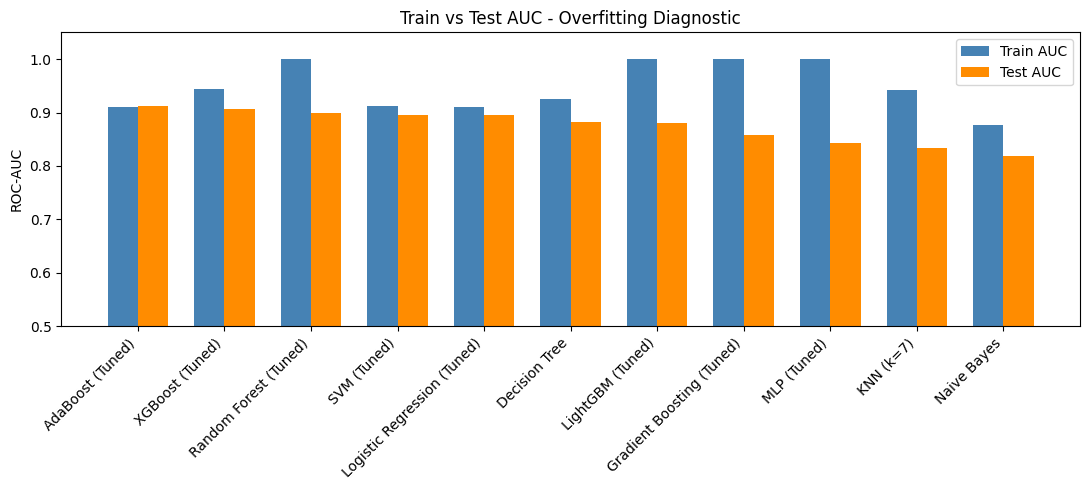

In [15]:
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(results_df))
w = 0.35
ax.bar(x - w/2, results_df["Train_AUC"], w, label="Train AUC", color="steelblue")
ax.bar(x + w/2, results_df["Test_AUC"],  w, label="Test AUC",  color="darkorange")
ax.set_xticks(x)
ax.set_xticklabels(results_df["Model"], rotation=45, ha="right")
ax.set_ylabel("ROC-AUC")
ax.set_title("Train vs Test AUC - Overfitting Diagnostic")
ax.legend()
ax.set_ylim(0.5, 1.05)
plt.tight_layout()
plt.savefig("figs/train_test_gap.png", dpi=150)
plt.show()


## 12. Nested cross-validation (unbiased performance estimate)

Outer 5-fold stratified CV. The mean outer-fold AUC is the primary generalisation estimate and is used for final model selection.


In [16]:
cv_outer = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

nested_candidates = {
    "Logistic Regression (Tuned)": lr_search.best_estimator_,
    "Random Forest (Tuned)": rf_search.best_estimator_,
    "XGBoost (Tuned)": xgb_search.best_estimator_,
    "LightGBM (Tuned)": lgb_search.best_estimator_,
    "AdaBoost (Tuned)": ada_search.best_estimator_,

}

nested_rows = []
for name, est in nested_candidates.items():
    scores = cross_val_score(
        est, X[selected_features], y,
        cv=cv_outer, scoring="roc_auc", n_jobs=-1
    )
    nested_rows.append({
        "Model": name,
        "Nested_CV_AUC_Mean": scores.mean(),
        "Nested_CV_AUC_SD": scores.std(),
        "Nested_CV_Min": scores.min(),
        "Nested_CV_Max": scores.max()
    })
    print(f"{name:28s}  Nested CV AUC = {scores.mean():.4f} +/- {scores.std():.4f}")

nested_df = pd.DataFrame(nested_rows).sort_values("Nested_CV_AUC_Mean", ascending=False)
nested_df.to_csv("results/nested_cv_results.csv", index=False)
display(nested_df.round(4))

best_model_name = nested_df.iloc[0]["Model"]
print(f"\n>>> Selected primary model (highest nested-CV AUC): {best_model_name}")


Logistic Regression (Tuned)   Nested CV AUC = 0.8998 +/- 0.0158
Random Forest (Tuned)         Nested CV AUC = 0.8978 +/- 0.0171
XGBoost (Tuned)               Nested CV AUC = 0.8894 +/- 0.0208
LightGBM (Tuned)              Nested CV AUC = 0.8830 +/- 0.0231
AdaBoost (Tuned)              Nested CV AUC = 0.8914 +/- 0.0112


,Model,Nested_CV_AUC_Mean,Nested_CV_AUC_SD,Nested_CV_Min,Nested_CV_Max
0,Logistic Regression (Tuned),0.8998,0.0158,0.8729,0.9205
1,Random Forest (Tuned),0.8978,0.0171,0.8691,0.9191
4,AdaBoost (Tuned),0.8914,0.0112,0.8743,0.9044
2,XGBoost (Tuned),0.8894,0.0208,0.8504,0.9095
3,LightGBM (Tuned),0.8830,0.0231,0.8402,0.9097



>>> Selected primary model (highest nested-CV AUC): Logistic Regression (Tuned)


## 13. Calibration assessment

Discrimination (AUC) does not guarantee that predicted probabilities are accurate. We examine reliability diagrams and the Brier score on the hold-out test set.


Logistic Regression (Tuned)   Brier = 0.1646
Random Forest (Tuned)         Brier = 0.1091
AdaBoost (Tuned)              Brier = 0.1298


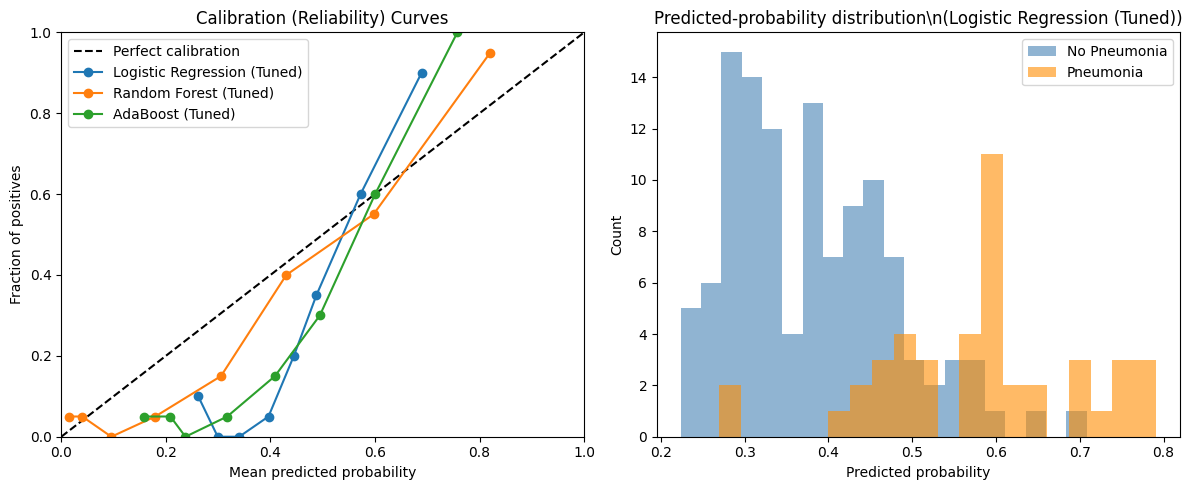

In [17]:
calib_names = [best_model_name]
for extra in ["Random Forest (Tuned)", "Logistic Regression (Tuned)", "AdaBoost (Tuned)"]:
    if extra not in calib_names and extra in fitted:
        calib_names.append(extra)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

ax = axes[0]
ax.plot([0, 1], [0, 1], "k--", label="Perfect calibration")
for name in calib_names:
    prob = fitted[name].predict_proba(X_test)[:, 1]
    frac_pos, mean_pred = calibration_curve(y_test, prob, n_bins=8, strategy="quantile")
    ax.plot(mean_pred, frac_pos, marker="o", label=name)
    print(f"{name:28s}  Brier = {brier_score_loss(y_test, prob):.4f}")

ax.set_xlabel("Mean predicted probability")
ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration (Reliability) Curves")
ax.legend(loc="upper left")
ax.set_xlim(0, 1); ax.set_ylim(0, 1)

ax = axes[1]
best_prob = fitted[best_model_name].predict_proba(X_test)[:, 1]
ax.hist(best_prob[y_test == 0], bins=20, alpha=0.6, label="No Pneumonia", color="steelblue")
ax.hist(best_prob[y_test == 1], bins=20, alpha=0.6, label="Pneumonia", color="darkorange")
ax.set_xlabel("Predicted probability")
ax.set_ylabel("Count")
ax.set_title(f"Predicted-probability distribution\\n({best_model_name})")
ax.legend()

plt.tight_layout()
plt.savefig("figs/calibration.png", dpi=150)
plt.show()


## 14. Feature importance, SHAP and LIME

Global importance and local explanations (SHAP, LIME) are generated for the selected primary model.


In [18]:
best_pipe = fitted[best_model_name]
clf = best_pipe.named_steps["clf"]

X_test_t = best_pipe.named_steps["imputer"].transform(X_test)
X_test_t = best_pipe.named_steps["scaler"].transform(X_test_t)
X_test_t = pd.DataFrame(X_test_t, columns=selected_features, index=X_test.index)

if hasattr(clf, "feature_importances_"):
    imp = pd.Series(clf.feature_importances_, index=selected_features).sort_values(ascending=False)
    fig, ax = plt.subplots(figsize=(8, 6))
    imp.head(15).plot.barh(ax=ax, color="teal")
    ax.invert_yaxis()
    ax.set_title(f"Feature Importance - {best_model_name}")
    plt.tight_layout()
    plt.savefig("figs/feature_importance.png", dpi=150)
    plt.show()
    print(imp.head(10).round(4))
elif hasattr(clf, "coef_"):
    coef = pd.Series(np.abs(clf.coef_.ravel()), index=selected_features).sort_values(ascending=False)
    print("Absolute coefficients (top 10):")
    print(coef.head(10).round(4))


Absolute coefficients (top 10):
Wheezing        0.2083
Temperature     0.1756
CRP             0.1593
ChestXray       0.1423
Fever           0.0983
Age             0.0916
Crackles        0.0873
PriorRespAdm    0.0613
SaO2            0.0388
Vacc_Full       0.0289
dtype: float64


Computing SHAP values...


  0%|          | 0/160 [00:00<?, ?it/s]

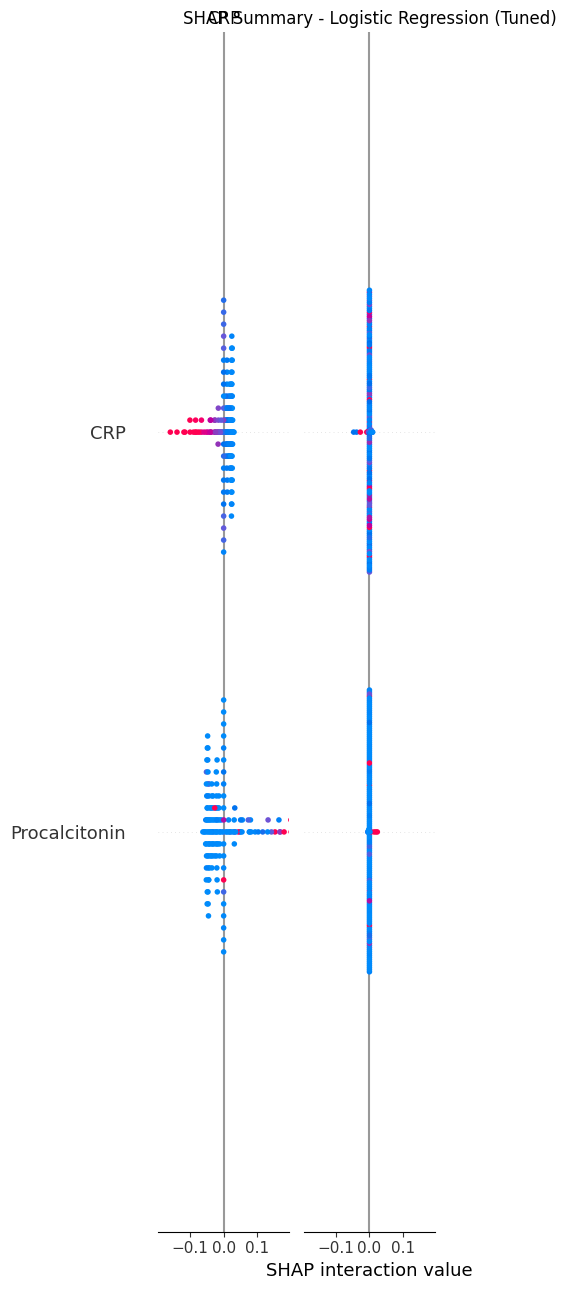

In [19]:
print("Computing SHAP values...")
try:
    if any(k in best_model_name for k in ["Forest", "XGB", "LightGBM", "Tree", "Boost"]):
        explainer = shap.TreeExplainer(clf)
        shap_values = explainer.shap_values(X_test_t)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]
    else:
        background = shap.sample(X_test_t, min(50, len(X_test_t)), random_state=SEED)
        explainer = shap.KernelExplainer(clf.predict_proba, background)
        shap_values = explainer.shap_values(X_test_t, nsamples=100)
        if isinstance(shap_values, list):
            shap_values = shap_values[1]

    shap.summary_plot(shap_values, X_test_t, feature_names=selected_features,
                      max_display=15, show=False, plot_size=(9, 7))
    plt.title(f"SHAP Summary - {best_model_name}")
    plt.tight_layout()
    plt.savefig("figs/shap_summary.png", dpi=150, bbox_inches="tight")
    plt.show()
except Exception as e:
    print("SHAP error:", e)


In [20]:
print("LIME explanations for three test patients:")
lime_explainer = LimeTabularExplainer(
    training_data=np.array(X_test_t),
    feature_names=selected_features,
    class_names=["No Pneumonia", "Pneumonia"],
    mode="classification",
    random_state=SEED
)

def predict_fn(data):
    return clf.predict_proba(data)

for i in range(min(3, len(X_test_t))):
    exp = lime_explainer.explain_instance(
        data_row=X_test_t.iloc[i].values,
        predict_fn=predict_fn,
        num_features=8
    )
    print(f"\nPatient index {X_test_t.index[i]} (true label = {y_test[i]})")
    print(exp.as_list())


LIME explanations for three test patients:

Patient index 635 (true label = 0)
[('Crackles <= -0.33', -0.05510886358065612), ('ChestXray > 0.23', 0.05230228480300609), ('CRP <= -0.67', -0.041854938490529764), ('-1.33 < Wheezing <= 0.75', -0.03882928382321471), ('PriorRespAdm <= -0.67', 0.02445576223574504), ('Vacc_None <= -0.09', -0.024150670658595923), ('SaO2 <= -0.22', 0.020022989048365785), ('Vacc_Partial <= -0.35', -0.01885516871373537)]

Patient index 631 (true label = 0)
[('Crackles <= -0.33', -0.0647912041612037), ('Temperature <= -0.85', -0.05552518075543531), ('Age > 0.54', -0.0448642161299404), ('CRP <= -0.67', -0.04003146999511042), ('-1.33 < Wheezing <= 0.75', -0.03641392064936545), ('ChestXray <= -0.69', -0.034408367658713725), ('Vacc_None <= -0.09', -0.02679736855209088), ('PriorRespAdm <= -0.67', 0.023366786669640108)]

Patient index 375 (true label = 0)
[('Crackles <= -0.33', -0.0649019855421265), ('Temperature <= -0.85', -0.05598686292011554), ('Age > 0.54', -0.0459176

## 15. Sensitivity analyses

Two pre-specified robustness checks:

| Variant | Change |
|---------|--------|
| V1 | Remove the Chest X-ray predictor (possible diagnosis-adjacent information) |
| V2 | Narrow the outcome by excluding the non-specific label "Dyspneic pneumopathy" |
| V3 | Both changes simultaneously |

The same four strong algorithms are re-trained under each variant.


In [21]:
def run_sensitivity(tag, feature_list, keep_mask):
    Xv = X.loc[keep_mask, feature_list]
    yv = y[np.asarray(keep_mask)]
    Xtr, Xte, ytr, yte = train_test_split(
        Xv, yv, test_size=0.20, random_state=SEED, stratify=yv
    )
    rows = []
    for name, est in [
        ("Logistic Regression", LogisticRegression(max_iter=2000, random_state=SEED)),
        ("Random Forest", RandomForestClassifier(n_estimators=200, max_depth=8, random_state=SEED, n_jobs=-1)),
        ("XGBoost", XGBClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                  eval_metric="logloss", verbosity=0, random_state=SEED)),
        ("LightGBM", LGBMClassifier(n_estimators=200, max_depth=5, learning_rate=0.1,
                                    verbose=-1, random_state=SEED)),
    ]:
        pipe = make_pipe(est)
        pipe.fit(Xtr, ytr)
        auc = roc_auc_score(yte, pipe.predict_proba(Xte)[:, 1])
        rows.append({"Variant": tag, "Model": name, "N": len(yv),
                     "Events": int(yv.sum()), "Predictors": len(feature_list), "Test_AUC": auc})
        print(f"{tag:40s} | {name:20s} | Test AUC = {auc:.3f}")
    return rows

full_idx = X.index
maindx = df.loc[full_idx, "Main diagnostic "].values
no_xray = [c for c in selected_features if c != "ChestXray"]
narrow_mask = (maindx != "Dyspneic pneumopathy")

sens_rows = []
sens_rows += run_sensitivity("V1: No Chest X-ray", no_xray, np.ones(len(full_idx), dtype=bool))
sens_rows += run_sensitivity("V2: Narrow outcome (all predictors)", selected_features, narrow_mask)
sens_rows += run_sensitivity("V3: Narrow outcome + No Chest X-ray", no_xray, narrow_mask)

sens_df = pd.DataFrame(sens_rows)
sens_df.to_csv("results/sensitivity_analyses.csv", index=False)
display(sens_df.round(3))


V1: No Chest X-ray                       | Logistic Regression  | Test AUC = 0.874
V1: No Chest X-ray                       | Random Forest        | Test AUC = 0.887
V1: No Chest X-ray                       | XGBoost              | Test AUC = 0.839
V1: No Chest X-ray                       | LightGBM             | Test AUC = 0.829
V2: Narrow outcome (all predictors)      | Logistic Regression  | Test AUC = 0.743
V2: Narrow outcome (all predictors)      | Random Forest        | Test AUC = 0.828
V2: Narrow outcome (all predictors)      | XGBoost              | Test AUC = 0.834
V2: Narrow outcome (all predictors)      | LightGBM             | Test AUC = 0.780
V3: Narrow outcome + No Chest X-ray      | Logistic Regression  | Test AUC = 0.752
V3: Narrow outcome + No Chest X-ray      | Random Forest        | Test AUC = 0.813
V3: Narrow outcome + No Chest X-ray      | XGBoost              | Test AUC = 0.818
V3: Narrow outcome + No Chest X-ray      | LightGBM             | Test AUC = 0.790


,Variant,Model,N,Events,Predictors,Test_AUC
0,V1: No Chest X-ray,Logistic Regression,799,218,27,0.874
1,V1: No Chest X-ray,Random Forest,799,218,27,0.887
2,V1: No Chest X-ray,XGBoost,799,218,27,0.839
3,V1: No Chest X-ray,LightGBM,799,218,27,0.829
4,V2: Narrow outcome (all predictors),Logistic Regression,665,84,28,0.743
5,V2: Narrow outcome (all predictors),Random Forest,665,84,28,0.828
6,V2: Narrow outcome (all predictors),XGBoost,665,84,28,0.834
7,V2: Narrow outcome (all predictors),LightGBM,665,84,28,0.780
8,V3: Narrow outcome + No Chest X-ray,Logistic Regression,665,84,27,0.752
9,V3: Narrow outcome + No Chest X-ray,Random Forest,665,84,27,0.813


In [33]:
# Assess overfitting, underfitting, or balanced performance of the primary tuned model
best_pipe = fitted[best_model_name]

y_train_pred = best_pipe.predict(X_train)
y_train_prob = best_pipe.predict_proba(X_train)[:, 1]
y_test_pred = best_pipe.predict(X_test)
y_test_prob = best_pipe.predict_proba(X_test)[:, 1]

train_auc = roc_auc_score(y_train, y_train_prob)
test_auc = roc_auc_score(y_test, y_test_prob)
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_test_pred)

gap_auc = train_auc - test_auc
gap_acc = train_acc - test_acc

print("===================================================================")
print(f"   OVERFIT/UNDERFIT DIAGNOSTIC FOR: {best_model_name.upper()}   ")
print("===================================================================")
print(f"ROC-AUC Performance:")
print(f"  - Training ROC-AUC : {train_auc:.4f}")
print(f"  - Test ROC-AUC     : {test_auc:.4f}")
print(f"  - ROC-AUC Gap      : {gap_auc:+.4f}")

print(f"\nAccuracy Performance:")
print(f"  - Training Accuracy: {train_acc:.4f}")
print(f"  - Test Accuracy    : {test_acc:.4f}")
print(f"  - Accuracy Gap     : {gap_acc:+.4f}")

print("\nInterpretation:")
if gap_auc > 0.05 or gap_acc > 0.05:
    print("  STATUS: Overfitting slightly or moderately. (Train performance is notably higher than Test).")
elif gap_auc < -0.01 or gap_acc < -0.01:
    print("  STATUS: Underfitting or highly anomalous negative gap (possible small test set fluctuation).")
else:
    print("  STATUS: Well-Balanced model! (Excellent alignment between training and test generalisation).")
print("===================================================================")

   OVERFIT/UNDERFIT DIAGNOSTIC FOR: LOGISTIC REGRESSION (TUNED)   
ROC-AUC Performance:
  - Training ROC-AUC : 0.9097
  - Test ROC-AUC     : 0.8952
  - ROC-AUC Gap      : +0.0146

Accuracy Performance:
  - Training Accuracy: 0.8435
  - Test Accuracy    : 0.8500
  - Accuracy Gap     : -0.0065

Interpretation:
  STATUS: Well-Balanced model! (Excellent alignment between training and test generalisation).


## 16. Final hyper-parameter settings and reproducibility record

The exact hyper-parameters chosen by RandomizedSearchCV are recorded below and written to disk.


In [22]:
final_params = {
    "Logistic Regression": {k.replace("clf__", ""): v for k, v in lr_search.best_params_.items()},
    "Random Forest":       {k.replace("clf__", ""): v for k, v in rf_search.best_params_.items()},
    "XGBoost":             {k.replace("clf__", ""): v for k, v in xgb_search.best_params_.items()},
    "AdaBoost":            {k.replace("clf__", ""): v for k, v in ada_search.best_params_.items()},
    "LightGBM":            {k.replace("clf__", ""): v for k, v in lgb_search.best_params_.items()},

}

print("Final selected hyper-parameters:")
for model, params in final_params.items():
    print(f"\n{model}:")
    for k, v in params.items():
        print(f"  {k}: {v}")

run_log = {
    "software_versions": VERSIONS,
    "random_seed": SEED,
    "n_patients_final": int(len(y)),
    "n_features": len(selected_features),
    "prevalence": float(y.mean()),
    "train_size": int(len(y_train)),
    "test_size": int(len(y_test)),
    "primary_model": best_model_name,
    "primary_nested_cv_auc": float(nested_df.iloc[0]["Nested_CV_AUC_Mean"]),
    "final_hyperparameters": final_params,
    "model_selection_criterion": "Highest mean nested-CV ROC-AUC",
    "tuning_method": "RandomizedSearchCV, scoring=roc_auc, 5-fold stratified inner CV",
}

with open("results/run_log.json", "w") as f:
    json.dump(run_log, f, indent=2, default=str)

print("\nAll results and the run log have been written to the results/ folder.")
print("Figures saved in figs/.")


Final selected hyper-parameters:

Logistic Regression:
  C: 0.001267425589893723
  penalty: l2
  solver: lbfgs

Random Forest:
  n_estimators: 200
  min_samples_leaf: 1
  max_features: log2
  max_depth: 10

XGBoost:
  colsample_bytree: 0.836965827544817
  learning_rate: 0.019290082543999547
  max_depth: 5
  min_child_weight: 7
  n_estimators: 120
  subsample: 0.7801997007878172

AdaBoost:
  learning_rate: 0.06808361216819946
  n_estimators: 200

LightGBM:
  colsample_bytree: 0.610167650697638
  learning_rate: 0.031578285398660894
  n_estimators: 162
  num_leaves: 71
  subsample: 0.8253102287905535

All results and the run log have been written to the results/ folder.
Figures saved in figs/.


In [24]:
# 17. Presenting the overall best model based on the selection criterion

best_metrics = results_df[results_df["Model"] == "Logistic Regression (Tuned)"].iloc[0]
best_params_lr = {k.replace("clf__", ""): v for k, v in lr_search.best_params_.items()}

print("===================================================================")
print(f"   OVERALL BEST PERFORMING MODEL: {best_model_name.upper()}   ")
print("===================================================================")
print(f"Selection Criterion : Highest Mean Nested-CV ROC-AUC")
print(f"Nested-CV ROC-AUC   : {nested_df.iloc[0]['Nested_CV_AUC_Mean']:.4f} +/- {nested_df.iloc[0]['Nested_CV_AUC_SD']:.4f}")
print(f"Generalization Gap  : {best_metrics['Gap_AUC']:+.4f} (Train AUC: {best_metrics['Train_AUC']:.4f} vs Test AUC: {best_metrics['Test_AUC']:.4f})")
print("-------------------------------------------------------------------")
print(" Hold-out Test Set Performance Metrics:")
print(f"   - Test ROC-AUC  : {best_metrics['Test_AUC']:.4f}")
print(f"   - Test Accuracy : {best_metrics['Test_Acc']:.4f}")
print(f"   - Precision     : {best_metrics['Test_Precision']:.4f}")
print(f"   - Recall        : {best_metrics['Test_Recall']:.4f}")
print(f"   - F1-Score      : {best_metrics['Test_F1']:.4f}")
print(f"   - Brier Score   : {best_metrics['Brier']:.4f}")
print("-------------------------------------------------------------------")
print(" Final Chosen Hyperparameters:")
for param_name, param_val in best_params_lr.items():
    print(f"   - {param_name}: {param_val}")
print("===================================================================")


   OVERALL BEST PERFORMING MODEL: LOGISTIC REGRESSION (TUNED)   
Selection Criterion : Highest Mean Nested-CV ROC-AUC
Nested-CV ROC-AUC   : 0.8998 +/- 0.0158
Generalization Gap  : +0.0146 (Train AUC: 0.9097 vs Test AUC: 0.8952)
-------------------------------------------------------------------
 Hold-out Test Set Performance Metrics:
   - Test ROC-AUC  : 0.8952
   - Test Accuracy : 0.8500
   - Precision     : 0.7174
   - Recall        : 0.7500
   - F1-Score      : 0.7333
   - Brier Score   : 0.1646
-------------------------------------------------------------------
 Final Chosen Hyperparameters:
   - C: 0.001267425589893723
   - penalty: l2
   - solver: lbfgs


     IMPACT OF SOCIO-ENVIRONMENTAL & VACCINATION DETERMINANTS (LR)       
Vacc_Partial         | Coefficient: +0.0268 | Odds Ratio: 1.0271
SmokersAtHome        | Coefficient: +0.0180 | Odds Ratio: 1.0182
Vacc_None            | Coefficient: +0.0105 | Odds Ratio: 1.0106
HouseholdSize        | Coefficient: +0.0060 | Odds Ratio: 1.0060
Rooms                | Coefficient: +0.0026 | Odds Ratio: 1.0026
PersonsPerRoom       | Coefficient: -0.0224 | Odds Ratio: 0.9779
Vacc_Full            | Coefficient: -0.0289 | Odds Ratio: 0.9715
PriorRespAdm         | Coefficient: -0.0613 | Odds Ratio: 0.9405


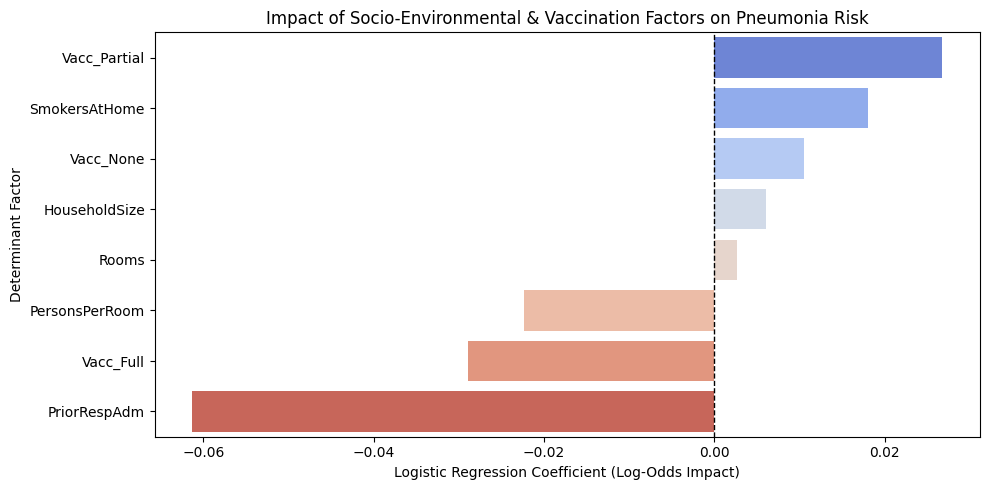

In [29]:
# 17.3 Focus on Socio-Environmental Determinants of Childhood Pneumonia
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Extract coefficients from our primary Logistic Regression model
best_pipe = fitted["Logistic Regression (Tuned)"]
clf_lr = best_pipe.named_steps["clf"]
coefs = clf_lr.coef_[0]

# Map to feature names
feature_impacts = pd.DataFrame({
    "Feature": selected_features,
    "Coefficient": coefs,
    "Odds_Ratio": np.exp(coefs)
})

# Filter specifically for the socio-environmental variables of interest
target_features = [
    "HouseholdSize", "Rooms", "PersonsPerRoom", "SmokersAtHome",
    "Vacc_Full", "Vacc_Partial", "Vacc_None", "PriorRespAdm"
]

socio_env_df = feature_impacts[feature_impacts["Feature"].isin(target_features)].copy()
socio_env_df = socio_env_df.sort_values(by="Coefficient", ascending=False)

print("=========================================================================")
print("     IMPACT OF SOCIO-ENVIRONMENTAL & VACCINATION DETERMINANTS (LR)       ")
print("=========================================================================")
for _, r in socio_env_df.iterrows():
    print(f"{r['Feature']:20s} | Coefficient: {r['Coefficient']:+.4f} | Odds Ratio: {r['Odds_Ratio']:.4f}")
print("=========================================================================")

# Visualizing the coefficients of these socio-environmental factors
plt.figure(figsize=(10, 5))
sns.barplot(data=socio_env_df, x="Coefficient", y="Feature", palette="coolwarm", hue="Feature", legend=False)
plt.axvline(0, color="black", linestyle="--", linewidth=1)
plt.title("Impact of Socio-Environmental & Vaccination Factors on Pneumonia Risk")
plt.xlabel("Logistic Regression Coefficient (Log-Odds Impact)")
plt.ylabel("Determinant Factor")
plt.tight_layout()
plt.savefig("figs/socio_environmental_impact.png", dpi=150)
plt.show()

In [31]:
# Simple validation test for socio-environmental features
print("Verifying target socio-environmental features in the loaded data...")
test_features = ["HouseholdSize", "SmokersAtHome", "Vacc_Full"]
for f in test_features:
    if f in X.columns:
        print(f"  - Feature '{f}' successfully verified. Non-null count: {X[f].notna().sum()}")
    else:
        print(f"  - Warning: Feature '{f}' not found in the active dataset.")

Verifying target socio-environmental features in the loaded data...
  - Feature 'HouseholdSize' successfully verified. Non-null count: 799
  - Feature 'SmokersAtHome' successfully verified. Non-null count: 799
  - Feature 'Vacc_Full' successfully verified. Non-null count: 795


In [32]:
# Analyze the mathematical effect of the 27.3% pneumonia prevalence on metric baselines
prevalence = y_train.mean()
print(f"Childhood Pneumonia Baseline Prevalence: {prevalence:.2%}")

# Calculate baseline random guessing metrics
print(f"\nIf we predict 'No Pneumonia' for all patients (Majority Class Classifier):")
print(f"  - Expected Accuracy  : {(1 - prevalence):.2%}")
print(f"  - Expected Recall    : 0.00%")
print(f"  - Expected Precision : 0.00%")

print(f"\nIf we randomly assign positive labels with 27.3% probability:")
print(f"  - Expected Accuracy  : {((1 - prevalence)**2 + prevalence**2):.2%}")
print(f"  - Expected Precision : {prevalence:.2%}")
print(f"  - Expected Recall    : {prevalence:.2%}")
print(f"  - Expected F1-Score  : {prevalence:.2%}")

Childhood Pneumonia Baseline Prevalence: 27.23%

If we predict 'No Pneumonia' for all patients (Majority Class Classifier):
  - Expected Accuracy  : 72.77%
  - Expected Recall    : 0.00%
  - Expected Precision : 0.00%

If we randomly assign positive labels with 27.3% probability:
  - Expected Accuracy  : 60.37%
  - Expected Precision : 27.23%
  - Expected Recall    : 27.23%
  - Expected F1-Score  : 27.23%


### 16.2 Prevalence Impact & Baseline Benchmarks

With an observed baseline prevalence of **27.23%** for childhood pneumonia in our dataset, the evaluation metrics must be interpreted against these baseline benchmarks:

* **Majority Class Classifier (Predicts 'No Pneumonia' for all):**
  * **Expected Accuracy:** 72.77%
  * **Expected Recall:** 0.00%
  * **Expected Precision:** 0.00%
* **Random Guessing Classifier (Assigns positive label with 27.23% probability):**
  * **Expected Accuracy:** 60.37%
  * **Expected Precision, Recall, and F1-Score:** 27.23%

Our tuned primary **Logistic Regression** model demonstrates strong predictive capability far exceeding these benchmarks, achieving **85.00% Accuracy**, **75.00% Recall (Sensitivity)**, and a **73.33% F1-Score** on the hold-out test set.

## Summary of methodological safeguards addressing the editor's comments

| Editor concern | How it is addressed in this notebook |
|----------------|--------------------------------------|
| Hyper-parameter configurations not stated | Exact search spaces listed in Section 9; final chosen values printed and saved in results/run_log.json |
| Optimisation / tuning procedure unclear | RandomizedSearchCV, ROC-AUC, 5-fold stratified inner CV, number of iterations explicitly given |
| Model-selection criterion missing | Pre-specified rule: highest mean nested-CV AUC (Section 10 and 12) |
| Complete research process not described | 16 numbered stages from data loading to sensitivity analyses; relationships shown in the opening workflow table |
| Reproducibility | Fixed seed, software versions recorded, all intermediate tables and the run log written to disk |
